# Classifier Training: Original vs Modified Statements

Classifiers are trained on the 30 linguistic features (26 DeCLaRatiVE features plus four part-of-speech features) to distinguish original from modified statements, (i) across both attack modalities and (ii) separately for human and generative language model modifications.

**Evaluation pipeline**

1. Split the data into a training set (~80%) and a held-out test set (~20%), **grouped by statement**: the original and all modifications of a statement are always on the same side of the split. The same original statement was attacked more than once and appears once per attack sequence with identical features, so a split by row would place identical texts in both sets.
2. Select hyperparameters with 5-fold cross-validation on the training set only, with folds also grouped by statement.
3. Fit each selected model on the full training set and evaluate it once on the test set.

Performance is reported per class (original, modified), as in Table 2 of the manuscript. AUC uses *modified* as the positive class; F1 is macro-averaged over both classes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    confusion_matrix, roc_curve, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

## Configuration

In [2]:
ROOT       = Path('..').resolve()
DATA_PATH  = ROOT / 'output' / 'combined_long_liwc_lingfeat_linked.csv'
OUTPUT_DIR = ROOT / 'output'
SEED       = 42

# Metadata columns; every other column is a linguistic feature
META = ['text_type', 'attack_modality', 'rewrite_id', 'statement_id', 'topic_label',
        'original_veracity', 'target_veracity', 'original_label', 'rewrite_label', 'asr', 'text']

## Load Data

One row per text: the original statement and the modification (best attempt) of every attack sequence.

In [3]:
df = pd.read_csv(DATA_PATH, encoding='utf-8')
features = [c for c in df.columns if c not in META]

print(f'Rows: {len(df)}  |  Features: {len(features)}')
print(df['text_type'].value_counts().to_string())
print(pd.crosstab(df['attack_modality'], df['text_type']).to_string())
assert len(features) == 30, 'Expected 30 linguistic features'

Rows: 1002  |  Features: 30
text_type
original    501
rewrite     501
text_type        original  rewrite
attack_modality                   
human                 223      223
llm                   278      278


### Why the split is grouped by statement

The number of unique statements is smaller than the number of original rows: the same statement was attacked in several sequences and its original text (with identical features) appears once per sequence.

In [4]:
originals = df[df['text_type'] == 'original']
print(f'Original rows:          {len(originals)}')
print(f'Unique statements:      {originals["statement_id"].nunique()}')
print(f'Duplicated feature rows among originals: '
      f'{originals.duplicated(subset=features).sum()}')
for modality, part in originals.groupby('attack_modality'):
    print(f'  {modality}: {len(part)} original rows, {part["statement_id"].nunique()} unique statements')

Original rows:          501
Unique statements:      216
Duplicated feature rows among originals: 285
  human: 223 original rows, 148 unique statements
  llm: 278 original rows, 169 unique statements


## Classifiers and Hyperparameter Grids

In [5]:
model_configs = {
    'Logistic Regression': {
        'estimator': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=2000, random_state=SEED))
        ]),
        'param_grid': {'model__C': [0.1, 1.0, 10.0]}
    },
    'Random Forest': {
        'estimator': RandomForestClassifier(random_state=SEED),
        'param_grid': {
            'n_estimators': [100, 300],
            'max_depth': [None, 10, 20],
            'min_samples_leaf': [1, 2]
        }
    },
    'Gradient Boosting': {
        'estimator': GradientBoostingClassifier(random_state=SEED),
        'param_grid': {
            'n_estimators': [100, 200],
            'learning_rate': [0.05, 0.1],
            'max_depth': [2, 3]
        }
    },
    'SVM': {
        'estimator': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVC(kernel='rbf', probability=True, random_state=SEED))
        ]),
        'param_grid': {
            'model__C': [0.5, 1.0, 2.0],
            'model__gamma': ['scale', 0.1, 0.01]
        }
    }
}

## Training and Evaluation

`run_pipeline()` performs the grouped train/test split, selects hyperparameters with grouped 5-fold cross-validation on the training set, and evaluates each classifier once on the test set. It returns one row of test-set metrics per classifier, plus the fitted models and test data for the figures below.

In [6]:
def run_pipeline(data, name):
    y      = (data['text_type'] == 'rewrite').astype(int).to_numpy()   # original = 0, modified = 1
    X      = data[features].fillna(0).astype(float)
    groups = data['statement_id'].to_numpy()

    # Held-out test set: one fold of a 5-fold stratified group split (~20% of statements)
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    train_idx, test_idx = next(outer.split(X, y, groups))
    assert not set(groups[train_idx]) & set(groups[test_idx]), 'Statement in both sets'

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    print(f'{name}: train = {len(train_idx)} texts ({len(set(groups[train_idx]))} statements), '
          f'test = {len(test_idx)} texts ({len(set(groups[test_idx]))} statements)')

    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    rows, fitted = [], {}
    for clf_name, cfg in model_configs.items():
        grid = GridSearchCV(cfg['estimator'], cfg['param_grid'], scoring='f1_macro',
                            cv=inner, n_jobs=-1, refit=True)
        grid.fit(X_train, y_train, groups=groups[train_idx])
        model = grid.best_estimator_

        y_pred  = model.predict(X_test)
        y_score = model.predict_proba(X_test)[:, 1]
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_test, y_pred, labels=[0, 1], zero_division=0)

        rows.append({
            'Data': name,
            'Classifier': clf_name,
            'n_train': len(train_idx),
            'n_test': len(test_idx),
            'CV F1': grid.best_score_,
            'Accuracy': accuracy_score(y_test, y_pred),
            'F1': f1.mean(),
            'AUC': roc_auc_score(y_test, y_score),
            'Precision Original': prec[0],
            'Precision Modified': prec[1],
            'Recall Original': rec[0],
            'Recall Modified': rec[1],
            'Best parameters': grid.best_params_,
        })
        fitted[clf_name] = {'model': model, 'y_pred': y_pred, 'y_score': y_score}

    return pd.DataFrame(rows), {'X_test': X_test, 'y_test': y_test, 'models': fitted}


datasets = {
    'Overall':                   df,
    'Human':                     df[df['attack_modality'] == 'human'],
    'Generative language model': df[df['attack_modality'] == 'llm'],
}

results, fits = [], {}
for name, data in datasets.items():
    table, fits[name] = run_pipeline(data, name)
    results.append(table)
results = pd.concat(results, ignore_index=True)

Overall: train = 802 texts (168 statements), test = 200 texts (48 statements)
Human: train = 356 texts (116 statements), test = 90 texts (32 statements)
Generative language model: train = 442 texts (135 statements), test = 114 texts (34 statements)


## Results Tables

**Table 2** (manuscript): overall, logistic regression and random forest. **Table S15** (supplement): all classifiers, overall and per attack modality. Values are test-set performance. `CV F1` is the best mean cross-validated macro F1 on the training set, reported for transparency only.

In [7]:
metric_cols = ['Accuracy', 'F1', 'AUC', 'Precision Original', 'Precision Modified',
               'Recall Original', 'Recall Modified']

def format_table(table):
    out = table[['Data', 'Classifier', 'n_train', 'n_test'] + metric_cols].copy()
    out[metric_cols] = out[metric_cols].map(lambda v: f'{v:.2f}')
    return out

table_2 = results[(results['Data'] == 'Overall') &
                  (results['Classifier'].isin(['Logistic Regression', 'Random Forest']))]
print('Table 2')
display(format_table(table_2))

print('Table S15')
display(format_table(results))

print('Cross-validation and selected hyperparameters')
display(results[['Data', 'Classifier', 'CV F1', 'Best parameters']].round(3))

results.drop(columns='Best parameters').to_csv(
    OUTPUT_DIR / 'classifier_original_vs_modified.csv', index=False)

Table 2


,Data,Classifier,n_train,n_test,Accuracy,F1,AUC,Precision Original,Precision Modified,Recall Original,Recall Modified
0,Overall,Logistic Regression,802,200,0.80,0.79,0.89,0.79,0.80,0.81,0.78
1,Overall,Random Forest,802,200,0.81,0.80,0.90,0.88,0.76,0.71,0.90


Table S15


,Data,Classifier,n_train,n_test,Accuracy,F1,AUC,Precision Original,Precision Modified,Recall Original,Recall Modified
0,Overall,Logistic Regression,802,200,0.80,0.79,0.89,0.79,0.80,0.81,0.78
1,Overall,Random Forest,802,200,0.81,0.80,0.90,0.88,0.76,0.71,0.90
2,Overall,Gradient Boosting,802,200,0.81,0.81,0.91,0.84,0.78,0.76,0.86
3,Overall,SVM,802,200,0.81,0.81,0.89,0.76,0.89,0.91,0.71
4,Human,Logistic Regression,356,90,0.70,0.70,0.73,0.71,0.69,0.67,0.73
5,Human,Random Forest,356,90,0.77,0.76,0.83,0.83,0.72,0.67,0.87
6,Human,Gradient Boosting,356,90,0.78,0.78,0.84,0.82,0.75,0.71,0.84
7,Human,SVM,356,90,0.70,0.70,0.74,0.69,0.71,0.73,0.67
8,Generative language model,Logistic Regression,442,114,1.00,1.00,1.00,1.00,1.00,1.00,1.00
9,Generative language model,Random Forest,442,114,0.99,0.99,1.00,1.00,0.98,0.98,1.00


Cross-validation and selected hyperparameters


,Data,Classifier,CV F1,Best parameters
0,Overall,Logistic Regression,0.794,{'model__C': 10.0}
1,Overall,Random Forest,0.838,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es..."
2,Overall,Gradient Boosting,0.854,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est..."
3,Overall,SVM,0.821,"{'model__C': 1.0, 'model__gamma': 0.01}"
4,Human,Logistic Regression,0.640,{'model__C': 10.0}
5,Human,Random Forest,0.717,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
6,Human,Gradient Boosting,0.738,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
7,Human,SVM,0.705,"{'model__C': 1.0, 'model__gamma': 'scale'}"
8,Generative language model,Logistic Regression,0.968,{'model__C': 0.1}
9,Generative language model,Random Forest,0.955,"{'max_depth': None, 'min_samples_leaf': 2, 'n_..."


## Confusion Matrices (Test Set)

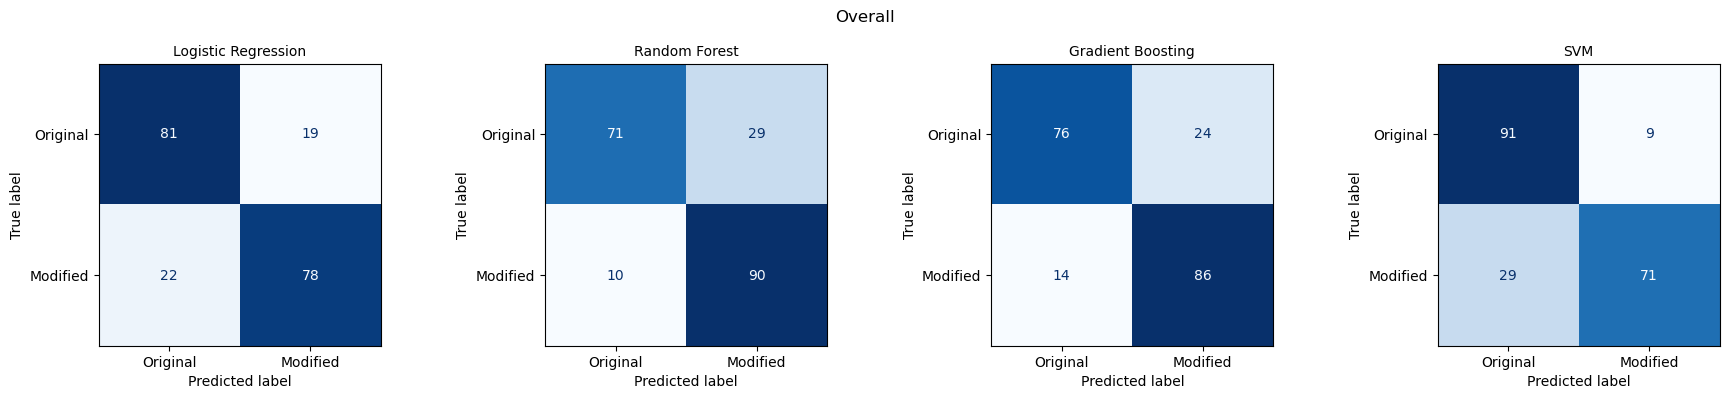

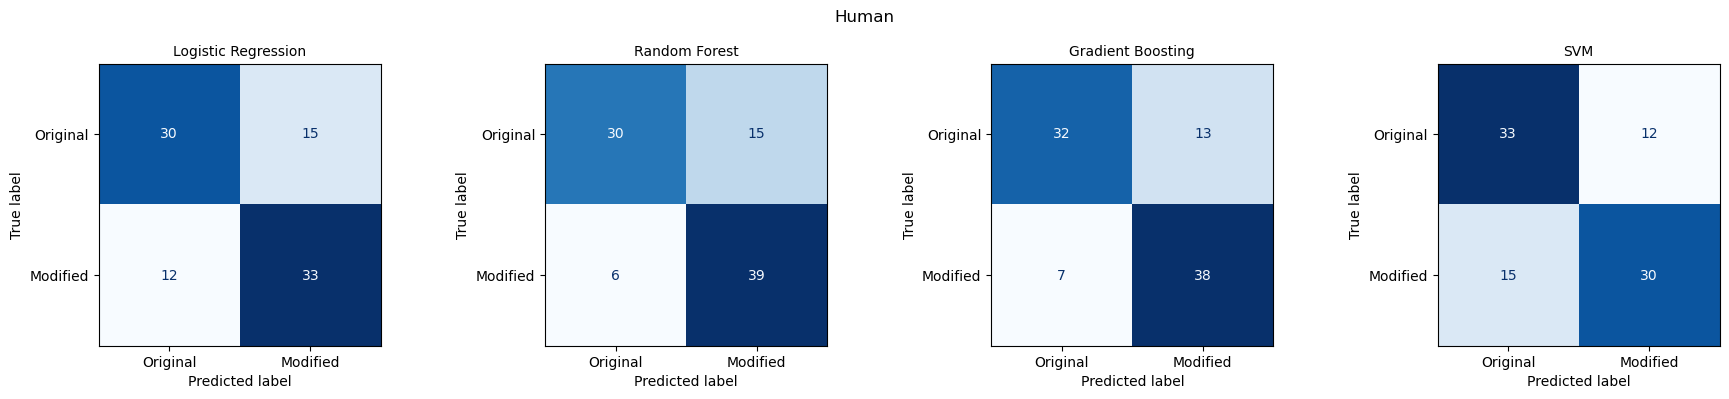

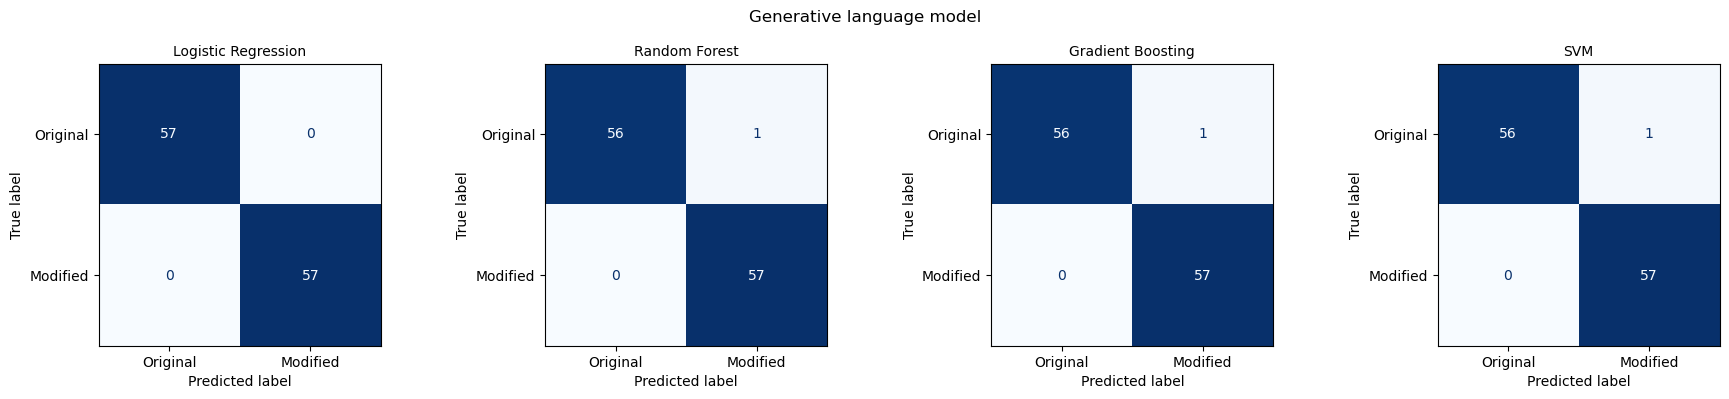

In [8]:
for name, fit in fits.items():
    fig, axes = plt.subplots(1, len(fit['models']), figsize=(4.5 * len(fit['models']), 4))
    for ax, (clf_name, res) in zip(axes, fit['models'].items()):
        ConfusionMatrixDisplay(
            confusion_matrix(fit['y_test'], res['y_pred']),
            display_labels=['Original', 'Modified']
        ).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
        ax.set_title(clf_name, fontsize=10)
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## ROC Curves (Test Set)

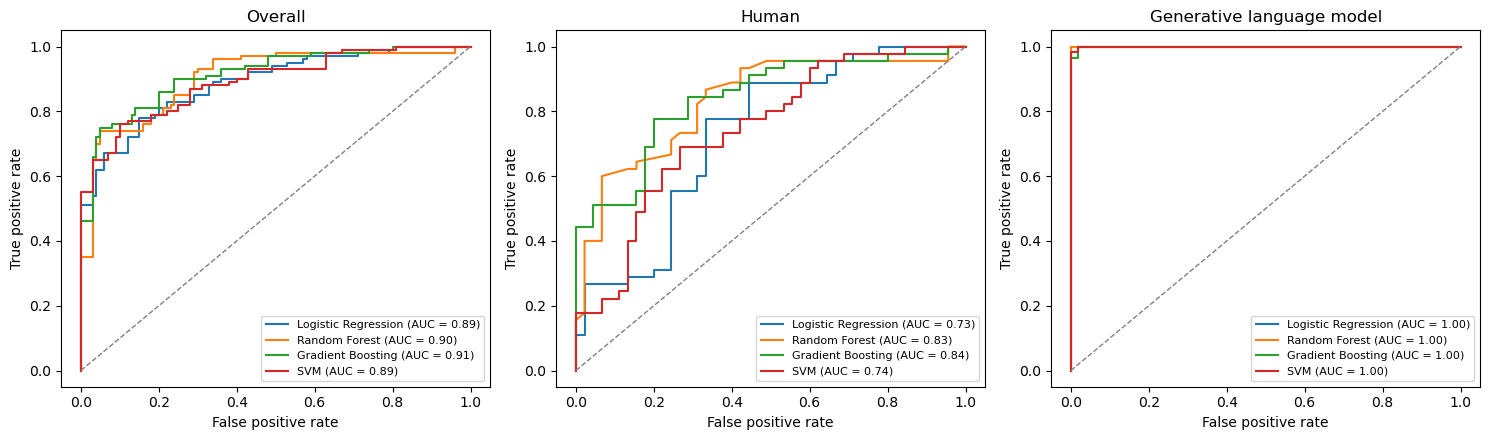

In [9]:
fig, axes = plt.subplots(1, len(fits), figsize=(5 * len(fits), 4.5))
for ax, (name, fit) in zip(axes, fits.items()):
    for clf_name, res in fit['models'].items():
        fpr, tpr, _ = roc_curve(fit['y_test'], res['y_score'])
        auc = roc_auc_score(fit['y_test'], res['y_score'])
        ax.plot(fpr, tpr, lw=1.5, label=f'{clf_name} (AUC = {auc:.2f})')
    ax.plot([0, 1], [0, 1], color='grey', lw=1, linestyle='--')
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')
    ax.set_title(name)
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

## Feature Importance

For each data set, permutation importance on the test set for the classifier with the highest test F1 (mean decrease in macro F1 over 20 repeats), and the standardized logistic regression coefficients (positive = more typical of modified statements).

In [ ]:
for name, fit in fits.items():
    best_name = results[results['Data'] == name].sort_values('F1', ascending=False)['Classifier'].iloc[0]
    best_model = fit['models'][best_name]['model']

    perm = permutation_importance(best_model, fit['X_test'], fit['y_test'],
                                  n_repeats=20, random_state=SEED, scoring='f1_macro', n_jobs=-1)
    perm_df = (pd.DataFrame({'feature': features,
                             'importance_mean': perm.importances_mean,
                             'importance_std': perm.importances_std})
               .sort_values('importance_mean', ascending=False))

    lr = fit['models']['Logistic Regression']['model'].named_steps['model']
    coefs = (pd.Series(lr.coef_[0], index=features)
             .sort_values(key=lambda s: s.abs(), ascending=False))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    top = perm_df.head(15).iloc[::-1]
    axes[0].barh(top['feature'], top['importance_mean'], xerr=top['importance_std'], color='teal')
    axes[0].set_xlabel('Permutation importance (decrease in macro F1)')
    axes[0].set_title(f'{name}: {best_name}')
    top_c = coefs.head(15).iloc[::-1]
    axes[1].barh(top_c.index, top_c.values,
                 color=['steelblue' if v > 0 else 'salmon' for v in top_c.values])
    axes[1].set_xlabel('Coefficient (standardized features)')
    axes[1].set_title(f'{name}: Logistic Regression')
    plt.tight_layout()
    plt.show()